# ML2 at 15 minutes: power per turbine and quarter hour, one week ahead (CARE)

**Why 15 minutes.** Production schedules in Romania are made per quarter hour, so ML2 must give one value every
15 minutes for the next 7 days (672 values per turbine), not one per hour.

**What stays the same as the hourly baseline** (`notebooks/care_ml2_power_baseline.md`). Sections 1 to 6 repeat its data
preparation unchanged: CARE comma variant, timelines with only identical overlaps merged, time-aligned groups, the
cleaning rules for available production, the hourly table, the forecast features and the two validation schemes.

**What is new** (sections 7 to 13):
- a quarter-hour table re-binned exactly from the 10-minute rows;
- 15-minute models whose wind input is the hourly wind interpolated to the quarter, because the forecast in
  `park_wind_forecast` stays hourly;
- the bar: the hourly ML2 model with its value repeated over the four quarters;
- a metric for the shape inside the hour, forecast-error sensitivity;
- a worked week ahead in 672 quarter-hour values;
- final models and a 15-minute feature contract.

The conventions of ML1 still hold: the time axis is `time_stamp`, exact zeros in temperatures are dropped readings,
and `status_type_id` is never a feature.

In [1]:
import io
import json
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
from catboost import CatBoostRegressor
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image as PILImage
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.notebook_repr_html", False)   # plain-text tables keep the notebook under the repo's 500 KB limit

ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "dataset" / "wind_turbine_scada_fault" / "raw"
CACHE = ROOT / "dataset" / "wind_turbine_scada_fault" / "cache"
OUT = CACHE / "ml2_15min"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models" / "ml2"
MODELS.mkdir(parents=True, exist_ok=True)
FOLDS_PATH = CACHE / "catboost_baseline" / "cv_folds.parquet"   # the ML1 folds, reused

FAST = False   # debugging only: subsample rows and use few trees

FARMS = ["A", "B", "C"]
# 10-minute columns per farm. ws = nacelle wind speed, p = active power (capacity factor), amb = ambient temperature,
# wdir = absolute wind direction (A and B only), p_avail = the turbine's own "possible / available power" (A and B only,
# used only to validate the curtailment rule). rotor and pitch feed only the diagnostic model.
COLS = {
    "A": dict(ws="wind_speed_3_avg", ws_max="wind_speed_3_max", ws_std="wind_speed_3_std", p="power_30_avg",
              amb="sensor_0_avg", wdir="sensor_1_avg", rotor="sensor_52_avg", pitch="sensor_5_avg", p_avail="power_29_avg"),
    "B": dict(ws="wind_speed_61_avg", ws_max="wind_speed_61_max", ws_std="wind_speed_61_std", p="power_62_avg",
              amb="sensor_8_avg", wdir="sensor_4_avg", rotor="sensor_25_avg", pitch="sensor_10_avg", p_avail="power_58_avg"),
    "C": dict(ws="wind_speed_236_avg", ws_max="wind_speed_236_max", ws_std="wind_speed_236_std", p="power_6_avg",
              amb="sensor_7_avg", wdir=None, rotor="sensor_144_avg", pitch="sensor_103_avg", p_avail=None),
}
VARS = ["ws", "ws_max", "ws_std", "p", "amb", "wdir", "rotor", "pitch", "p_avail"]

CUT_IN, RATED, CUT_OUT = 3.0, 13.0, 25.0   # theoretical curve, as in smarthack/wind/constants.py
REPAIR_DAYS = 14                           # removed after every anomaly window, as in ML1
OPER_LO, OPER_HI = 4.5, 20.0               # wind range (m/s) in which a healthy, unconstrained turbine must produce
STOP_P = 0.01                              # power at or below this inside the range = stopped
ENV_Q, CURT_FRAC, CURT_ABS = 0.90, 0.70, 0.05   # curtailed = power < 0.70 x envelope(ws) - 0.05 (section 3)
BIN = 0.5                                  # wind-speed bin width (m/s) for curves
MIN_ROWS_HOUR = 4                          # of 6 ten-minute rows: fewer clean rows and the hour has no target
WEEK_MIN_HOURS = 120                       # of 168: fewer clean hours and the 7-day window is not scored
FUTURE_FRAC = 0.80                         # future scheme: first 80% of every timeline's time span trains
SEED = 0
N_BOOT = 1000
CB_PARAMS = dict(depth=6, iterations=600, learning_rate=0.05, l2_leaf_reg=10, loss_function="RMSE",
                 thread_count=-1, verbose=False, allow_writing_files=False, random_seed=SEED)
INNER_MAX_ROWS = 150_000                   # rows per inner early-stopping fit
# Forecast error of hub-height wind speed by lead time (m/s, standard deviation) used for the sensitivity test. These are
# assumed typical values for NWP 100 m wind, NOT measured on our parks; see section 9.
NOISE_SD = {"day 1": 1.5, "day 3": 2.2, "day 7": 3.3}
NOISE_RHO = 0.95                           # hour-to-hour autocorrelation of the forecast error
N_NOISE = 3
if FAST:
    CB_PARAMS["iterations"] = 120
    N_BOOT = 200
    INNER_MAX_ROWS = 40_000

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#c9c8c2"
BLUE, ORANGE, AQUA, RED, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#c0392b", "#7d5ba6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})


def show(fig, name, dpi=80, colors=96):
    """Save the full-resolution PNG to the cache and show a small palette PNG inline (repo limit 500 KB per file)."""
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    img = PILImage.open(buf).convert("RGB").quantize(colors=colors)
    out = io.BytesIO()
    img.save(out, format="PNG", optimize=True)
    display(IPImage(out.getvalue()))


T0 = time.time()
print("root:", ROOT)

root: /Users/alexandrucojoaca/Documents/Smarthack


## 1. Load and check the known facts

Only the columns listed above are read, from every `comma_*.csv`. Exact zeros in ambient temperature become missing
(dropped readings), negative wind speeds become missing.

In [2]:
def dataset_paths(farm):
    return sorted((RAW / f"Wind Farm {farm}" / "datasets").glob("comma_*.csv"), key=lambda p: int(p.stem.split("_")[1]))


def read_dataset(job):
    farm, path = job
    m = {k: v for k, v in COLS[farm].items() if v}
    t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(
        include_columns=["time_stamp", "asset_id", "id", "train_test", "status_type_id"] + list(m.values())))
    d = pd.DataFrame({"time_stamp": t["time_stamp"].to_numpy().astype("datetime64[s]"),
                      "asset_id": t["asset_id"].to_numpy(), "id": t["id"].to_numpy(),
                      "status": t["status_type_id"].to_numpy()})
    for k in VARS:
        d[k] = t[m[k]].to_numpy(zero_copy_only=False).astype(np.float32) if k in m else np.float32(np.nan)
    d["farm"] = farm
    d["event_id"] = int(path.stem.split("_")[1])
    return d


with ThreadPoolExecutor(max_workers=6) as ex:
    D = pd.concat(list(ex.map(read_dataset, [(f, p) for f in FARMS for p in dataset_paths(f)])), ignore_index=True)
D["turbine"] = D["farm"] + D["asset_id"].map("{:02d}".format)
D.loc[D["amb"] == 0, "amb"] = np.nan
D.loc[D["ws"] < 0, "ws"] = np.nan

EVENTS_RAW = pd.concat([pd.read_csv(RAW / f"Wind Farm {f}" / "comma_event_info.csv", encoding="latin-1").assign(farm=f)
                        for f in FARMS], ignore_index=True)

facts = []
for f, g in D.groupby("farm"):
    facts.append({"farm": f, "datasets": g["event_id"].nunique(), "turbines": g["turbine"].nunique(),
                  "10-min rows": len(g), "power p99": round(float(g["p"].quantile(0.99)), 3),
                  "power max": round(float(g["p"].max()), 3), "rows with power < 0 (%)": round(100 * float((g["p"] < 0).mean()), 1),
                  "ambient median (C)": round(float(g["amb"].median()), 1),
                  "ambient p05..p95 (C)": f"{g['amb'].quantile(0.05):.1f}..{g['amb'].quantile(0.95):.1f}",
                  "absolute wind direction": COLS[f]["wdir"] or "none",
                  "available-power column": COLS[f]["p_avail"] or "none",
                  "wind p50 / p99 (m/s)": f"{g['ws'].median():.1f} / {g['ws'].quantile(0.99):.1f}"})
display(pd.DataFrame(facts).set_index("farm").T)
print(f"loaded {len(D):,} rows in {time.time() - T0:.0f} s")

farm                                A             B           C
datasets                           22            15          58
turbines                            5             9          22
10-min rows                   1196747        859065     3187136
power p99                       0.976         1.029       1.012
power max                       0.976         1.031       1.071
rows with power < 0 (%)          29.3          19.4        16.3
ambient median (C)               19.0          12.6        28.1
ambient p05..p95 (C)       12.0..30.0     5.2..20.8  20.0..36.3
absolute wind direction  sensor_1_avg  sensor_4_avg        none
available-power column   power_29_avg  power_58_avg        none
wind p50 / p99 (m/s)       5.5 / 16.9    8.1 / 21.2  6.9 / 20.3

loaded 5,242,948 rows in 7 s


Checked here: power is a capacity factor (p99 about 1.0 in every farm) and a sizeable share of rows is slightly negative
(consumption while idle). Farm C's ambient temperature is shifted (median about 28 C), so it is centred per farm before
use (section 5). Absolute wind direction exists only in A and B.

## 2. Timelines and time-aligned groups of turbines

**Timelines (same rule as ML1).** Datasets of the same turbine are merged only when their overlapping rows are identical;
12 of the 22 overlapping same-turbine pairs carry different data on the same anonymised timestamps.

**Time-aligned groups (new here).** The ordering metric needs turbines of the same park observed over the *same real
week*. Timestamps are anonymised per dataset, so a shared timestamp does not by itself mean a shared real time. Two
datasets of different turbines are put in the same time group when their hourly wind speeds correlate above 0.8 over at
least 3 shared days: turbines of one park see the same weather, unrelated periods do not.

In [3]:
def find_timelines(D):
    seg, pairs = {}, []
    for f in FARMS:
        d = D[D["farm"] == f]
        meta = d.groupby("event_id").agg(asset_id=("asset_id", "first"), start=("time_stamp", "min"))
        frames = {e: g.set_index("time_stamp")[["ws", "p", "amb"]] for e, g in d.groupby("event_id")}
        parent = {e: e for e in meta.index}

        def root(e):
            while parent[e] != e:
                e = parent[e]
            return e

        for a, g in meta.groupby("asset_id"):
            for i, j in combinations(g.sort_values("start").index, 2):
                x, y = frames[i], frames[j]
                common = x.index.intersection(y.index)
                if len(common) == 0:
                    continue
                X, Y = x.loc[common].to_numpy(), y.loc[common].to_numpy()
                same = float(((np.abs(X - Y) < 1e-6) | (np.isnan(X) & np.isnan(Y))).all(axis=1).mean())
                pairs.append(dict(farm=f, asset_id=a, dataset_1=i, dataset_2=j, overlap_days=round(len(common) / 144, 1),
                                  identical_share=round(same, 4)))
                if same > 0.99:
                    parent[root(i)] = root(j)
        comp = {e: root(e) for e in meta.index}
        for a, g in meta.groupby("asset_id"):
            roots = sorted({comp[e] for e in g.index}, key=lambda r: g.loc[[e for e in g.index if comp[e] == r], "start"].min())
            for k, r in enumerate(roots):
                for e in g.index:
                    if comp[e] == r:
                        seg[e] = f"{f}{a:02d}-{k}"
    return seg, pd.DataFrame(pairs)


SEG, PAIRS_OVERLAP = find_timelines(D)
D["segment"] = D["event_id"].map(SEG)
n_before = len(D)
D = D.sort_values(["segment", "time_stamp", "event_id"]).drop_duplicates(["segment", "time_stamp"]).reset_index(drop=True)
print(f"identical overlap rows removed: {n_before - len(D):,}")
ov = PAIRS_OVERLAP.assign(identical=PAIRS_OVERLAP["identical_share"] > 0.99).groupby("farm")["identical"].agg(["size", "sum"])
ov.columns = ["overlapping same-turbine pairs", "identical (merged)"]
ov["timelines"] = D.groupby("farm")["segment"].nunique()
display(ov)

identical overlap rows removed: 406,292


      overlapping same-turbine pairs  identical (merged)  timelines
farm                                                               
A                                  8                   5         17
B                                  1                   1         14
C                                 13                   4         54

In [4]:
def find_time_groups(D):
    hourly = D.assign(hour=D["time_stamp"].dt.floor("h")).groupby(["farm", "segment", "hour"])["ws"].mean()
    group, links = {}, []
    for f in FARMS:
        piv = hourly.loc[f].unstack("segment")
        segs = list(piv.columns)
        turb = {s: s.split("-")[0] for s in segs}
        parent = {s: s for s in segs}

        def root(s):
            while parent[s] != s:
                s = parent[s]
            return s

        valid = piv.notna().to_numpy()
        vals = piv.to_numpy()
        for a, b in combinations(range(len(segs)), 2):
            m = valid[:, a] & valid[:, b]
            if m.sum() < 72:
                continue
            c = float(np.corrcoef(vals[m, a], vals[m, b])[0, 1])
            links.append(dict(farm=f, segment_1=segs[a], segment_2=segs[b], same_turbine=turb[segs[a]] == turb[segs[b]],
                              shared_days=round(m.sum() / 24, 1), corr=round(c, 3)))
            if c > 0.8:
                parent[root(segs[a])] = root(segs[b])
        roots = sorted({root(s) for s in segs})
        for k, r in enumerate(roots):
            for s in segs:
                if root(s) == r:
                    group[s] = f"{f}g{k:02d}"
    links = pd.DataFrame(links)
    links["same_group"] = [group[a] == group[b] for a, b in zip(links["segment_1"], links["segment_2"])]
    return group, links


GROUP, LINKS = find_time_groups(D)
D["group"] = D["segment"].map(GROUP)
bad = LINKS[LINKS["same_turbine"] & LINKS["same_group"]]
assert bad.empty, "the same turbine shows different data at the same real time"
print("hourly wind correlation of overlapping timelines (different turbines): share in (0.5, 0.8):",
      round(float(((LINKS["corr"] > 0.5) & (LINKS["corr"] < 0.8) & ~LINKS["same_turbine"]).mean()), 3))
gs = D.groupby(["farm", "group"]).agg(timelines=("segment", "nunique"), turbines=("turbine", "nunique"))
gt = gs.groupby("farm").agg(groups=("turbines", "size"), groups_with_2plus_turbines=("turbines", lambda s: int((s >= 2).sum())),
                            largest_group_turbines=("turbines", "max"))
display(gt)

hourly wind correlation of overlapping timelines (different turbines): share in (0.5, 0.8): 0.0


      groups  groups_with_2plus_turbines  largest_group_turbines
farm                                                            
A          7                           5                       4
B          8                           5                       3
C         15                          15                       7

The correlations split cleanly: overlapping timelines of different turbines either track each other (r > 0.8) or not at
all, with nothing in between. Within a time group the anonymised timestamps therefore mark the same real hour for every
turbine, which is what the pairwise ordering test in section 8 needs. No turbine appears with different data inside one
group.

## 3. Target: available production

The target is the production of a **healthy turbine in operation, not held back**. Removed, in this order:
1. **Anomaly windows** (`event_start` .. `event_end`, located by `event_start_id` / `event_end_id`) and the **14 days of
   repair** after each window. Windows of normal datasets are reference periods and stay.
2. **Stops**: wind between 4.5 and 20 m/s but power at or below 0.01.
3. **Curtailment / derating**: wind between 4.5 and 20 m/s and power below `0.70 x envelope(ws) - 0.05`, where the
   envelope is the farm's 90th percentile of producing rows per 0.5 m/s wind bin (made monotone). The margin was chosen
   so the rule is conservative; it is validated below against the turbines' own available-power signal in A and B.

Rows below 4.5 m/s (start-up, small negative consumption) and at or above 20 m/s (storm control) are kept as they are:
there the low output is physics, not a fault. `status_type_id` is not used for the target; it is only compared.

In [5]:
def event_windows():
    """Anomaly windows located by event_start_id / event_end_id in each dataset's own rows (never by timestamp)."""
    rows = []
    for _, r in EVENTS_RAW[EVENTS_RAW["event_label"] == "anomaly"].iterrows():
        raw = read_ids(r["farm"], r["event_id"])
        s = raw.loc[raw["id"] == r["event_start_id"], "time_stamp"].iloc[0]
        e = raw.loc[raw["id"] == r["event_end_id"], "time_stamp"].iloc[0]
        rows.append(dict(farm=r["farm"], event_id=r["event_id"], segment=SEG[r["event_id"]], start=s, end=e))
    return pd.DataFrame(rows)


def read_ids(farm, event_id):
    t = pacsv.read_csv(RAW / f"Wind Farm {farm}" / "datasets" / f"comma_{event_id}.csv",
                       convert_options=pacsv.ConvertOptions(include_columns=["time_stamp", "id"]))
    return pd.DataFrame({"time_stamp": t["time_stamp"].to_numpy().astype("datetime64[s]"), "id": t["id"].to_numpy()})


EV = event_windows()
ts = D["time_stamp"].to_numpy()
seg_arr = D["segment"].to_numpy()
D["window"] = False
D["repair"] = False
seg_index = {s: np.flatnonzero(seg_arr == s) for s in D["segment"].unique()}
win, rep = np.zeros(len(D), bool), np.zeros(len(D), bool)
for _, r in EV.iterrows():
    idx = seg_index[r["segment"]]
    t = ts[idx]
    win[idx[(t >= np.datetime64(r["start"])) & (t <= np.datetime64(r["end"]))]] = True
    rep[idx[(t > np.datetime64(r["end"])) & (t <= np.datetime64(r["end"]) + np.timedelta64(REPAIR_DAYS, "D"))]] = True
D["window"], D["repair"] = win, rep & ~win
D["event_excl"] = D["window"] | D["repair"]
D["valid"] = D["ws"].notna() & D["p"].notna()
D["bin"] = np.floor(D["ws"].fillna(-1) / BIN).astype(int)
NBINS = int(40 / BIN)


def binned(ws_bin, values, stat, min_n=20):
    """Per wind bin statistic, interpolated over empty bins, indexed 0..NBINS-1."""
    s = pd.Series(values).groupby(np.asarray(ws_bin))
    s = s.quantile(stat) if isinstance(stat, float) else s.agg(stat)
    cnt = pd.Series(values).groupby(np.asarray(ws_bin)).size()
    s = s[cnt >= min_n]
    s = s[(s.index >= 0) & (s.index < NBINS)]
    return s.reindex(range(NBINS)).interpolate(limit_direction="both")


ENVELOPE, REF10 = {}, {}
for f in FARMS:
    m = (D["farm"] == f) & D["valid"] & ~D["event_excl"] & (D["p"] > STOP_P)
    ENVELOPE[f] = binned(D.loc[m, "bin"], D.loc[m, "p"].to_numpy(), ENV_Q).cummax()
fm = D["farm"].to_numpy()
env = np.full(len(D), np.nan)
for f in FARMS:
    i = fm == f
    env[i] = ENVELOPE[f].to_numpy()[np.clip(D["bin"].to_numpy()[i], 0, NBINS - 1)]
D["envelope"] = env
in_range = D["valid"] & (D["ws"] >= OPER_LO) & (D["ws"] < OPER_HI)
D["stop"] = in_range & (D["p"] <= STOP_P)
D["curtail"] = in_range & ~D["stop"] & (D["p"] < CURT_FRAC * D["envelope"] - CURT_ABS)
D["clean"] = D["valid"] & ~D["event_excl"] & ~D["stop"] & ~D["curtail"]
# empirical 10-minute available curve per farm (median of clean rows), used for availability and the averaging bias
for f in FARMS:
    m = (D["farm"] == f) & D["clean"]
    REF10[f] = binned(D.loc[m, "bin"], D.loc[m, "p"].to_numpy(), "median")
ref = np.full(len(D), np.nan)
for f in FARMS:
    i = fm == f
    ref[i] = REF10[f].to_numpy()[np.clip(D["bin"].to_numpy()[i], 0, NBINS - 1)]
D.loc[D["ws"].isna(), "bin"] = -1
D["ref10"] = np.where(D["ws"].notna(), ref, np.nan)

cut = []
for f, g in D.groupby("farm"):
    out = ~g["event_excl"]
    hi = g["valid"] & out & (g["ws"] >= 13) & (g["ws"] < OPER_HI)
    cut.append({"farm": f, "rows": len(g), "missing wind or power %": 100 * (~g["valid"]).mean(),
                "anomaly window %": 100 * g["window"].mean(), "repair 14 d %": 100 * g["repair"].mean(),
                "stop %": 100 * (g["stop"] & out).mean(), "curtailed %": 100 * (g["curtail"] & out).mean(),
                "clean %": 100 * g["clean"].mean(),
                "curtailed % of rows at 13-20 m/s": 100 * g.loc[hi, "curtail"].mean(),
                "stopped % of rows at 13-20 m/s": 100 * g.loc[hi, "stop"].mean()})
CUT = pd.DataFrame(cut).set_index("farm").round(2)
display(CUT)

         rows  missing wind or power %  anomaly window %  repair 14 d %  stop %  curtailed %  clean %  curtailed % of rows at 13-20 m/s  stopped % of rows at 13-20 m/s
farm                                                                                                                                                                   
A     1014782                     0.00              1.63           0.67    1.96         0.17    95.57                              0.69                            9.59
B      806909                     0.00              4.21           0.57    6.78        12.19    76.24                             53.19                            9.13
C     3014965                     0.06              2.02           0.48    6.48        11.58    79.37                             47.05                           10.35

**Validation of the curtailment rule against the turbines' own available power** (A: `power_29` "possible grid active
power", B: `power_58` "available power"). Truth = available minus actual above 0.1, inside the 4.5-20 m/s range and not
stopped. C has no such signal, so the rule is applied there unvalidated.

In [6]:
val = []
for f in ["A", "B"]:
    g = D[(D["farm"] == f) & D["valid"] & ~D["event_excl"] & (D["ws"] >= OPER_LO) & (D["ws"] < OPER_HI) & ~D["stop"]]
    truth = (g["p_avail"] - g["p"]) > 0.1
    flag = g["curtail"]
    hi = g["ws"] >= 13
    curve_rule = g.loc[hi & ~flag, "p"].mean()
    curve_truth = g.loc[hi & ~truth, "p"].mean()
    val.append({"farm": f, "truth: curtailed share %": 100 * truth.mean(), "rule: flagged share %": 100 * flag.mean(),
                "precision": (flag & truth).sum() / max(flag.sum(), 1), "recall": (flag & truth).sum() / max(truth.sum(), 1),
                "mean power at 13-20 m/s kept by rule": curve_rule, "same, kept by truth": curve_truth})
display(pd.DataFrame(val).set_index("farm").round(3))

      truth: curtailed share %  rule: flagged share %  precision  recall  mean power at 13-20 m/s kept by rule  same, kept by truth
farm                                                                                                                               
A                        0.314                  0.291      0.735   0.683                                 0.970                0.972
B                       28.038                 17.691      0.987   0.623                                 0.875                1.015

**Against `status_type_id`** (comparison only). Share of rows outside anomaly windows that each filter removes, and how
much the two agree.

In [7]:
st = []
for f, g in D[D["valid"] & ~D["event_excl"]].groupby("farm"):
    phys = g["stop"] | g["curtail"]
    stat = g["status"] != 0
    st.append({"farm": f, "status != 0 %": 100 * stat.mean(), "physical rule %": 100 * phys.mean(),
               "both %": 100 * (phys & stat).mean(), "status only %": 100 * (stat & ~phys).mean(),
               "physical only %": 100 * (phys & ~stat).mean(),
               "status mix of physical-only rows": g.loc[phys & ~stat, "status"].value_counts(normalize=True).round(2).to_dict()})
display(pd.DataFrame(st).set_index("farm").round(2))

      status != 0 %  physical rule %  both %  status only %  physical only % status mix of physical-only rows
farm                                                                                                         
A             24.75             2.18    1.77          22.98             0.40                         {0: 1.0}
B              9.97            19.93    7.28           2.69            12.65                         {0: 1.0}
C             10.54            18.54    6.91           3.63            11.63                         {0: 1.0}

**Availability per turbine** (outside anomaly windows and repair). Energy-based: actual energy divided by the energy the
turbine would have produced on its stopped and curtailed rows had it followed the farm's 10-minute available curve.
The loss is split into stops and curtailment. `expected production = available production x availability`.

In [8]:
def availability(d):
    d = d[d["valid"] & ~d["event_excl"]]
    pot = np.where(d["clean"], d["p"], d["ref10"])
    lost_stop = np.where(d["stop"], d["ref10"] - d["p"], 0.0)
    lost_curt = np.where(d["curtail"], np.maximum(d["ref10"] - d["p"], 0.0), 0.0)
    out = pd.DataFrame({"turbine": d["turbine"].to_numpy(), "pot": pot, "act": d["p"].to_numpy(), "ls": lost_stop, "lc": lost_curt})
    g = out.groupby("turbine").sum()
    return pd.DataFrame({"availability": g["act"] / g["pot"], "stop loss": g["ls"] / g["pot"], "curtailment loss": g["lc"] / g["pot"]})


AVAIL = availability(D)
AVAIL["farm"] = AVAIL.index.str[0]
display(AVAIL.groupby("farm").describe().T.round(3).loc[(slice(None), ["mean", "min", "50%", "max"]), :])
AVAIL.to_csv(OUT / "availability_per_turbine.csv")

farm                       A      B      C
availability     mean  0.956  0.802  0.786
                 min   0.930  0.737  0.622
                 50%   0.954  0.808  0.785
                 max   0.995  0.852  0.918
stop loss        mean  0.041  0.086  0.094
                 min   0.005  0.054  0.039
                 50%   0.045  0.075  0.083
                 max   0.067  0.155  0.213
curtailment loss mean  0.002  0.112  0.121
                 min   0.001  0.051  0.043
                 50%   0.003  0.118  0.117
                 max   0.003  0.130  0.198

Curtailment is the regime, not the exception, in B and C: at 13-20 m/s most rows are held below the curve while
`status_type_id` reads 0 (normal). The turbines' available-power signal in B confirms it (section 3 validation). This
limits what "available production" means in practice: the available curve is what a turbine *can* produce, the
availability factor (stops and curtailment) turns it into what the park *did* produce. Both are reported.

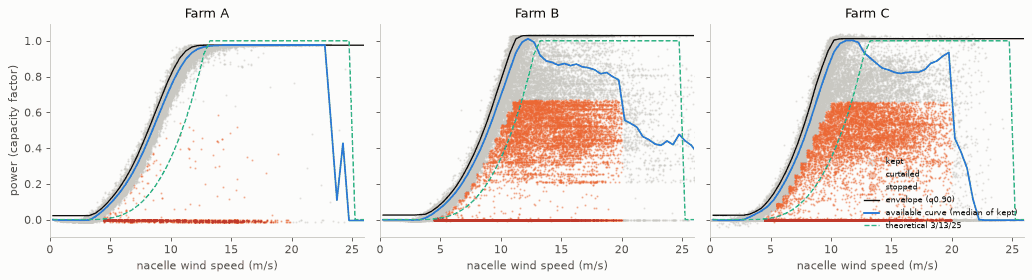

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, f in zip(axes, FARMS):
    g = D[(D["farm"] == f) & D["valid"] & ~D["event_excl"]].sample(60_000, random_state=0)
    ax.scatter(g.loc[g["clean"], "ws"], g.loc[g["clean"], "p"], s=1, c=MUTED, alpha=0.35, label="kept", rasterized=True)
    ax.scatter(g.loc[g["curtail"], "ws"], g.loc[g["curtail"], "p"], s=1, c=ORANGE, alpha=0.35, label="curtailed", rasterized=True)
    ax.scatter(g.loc[g["stop"], "ws"], g.loc[g["stop"], "p"], s=1, c=RED, alpha=0.35, label="stopped", rasterized=True)
    x = (np.arange(NBINS) + 0.5) * BIN
    ax.plot(x, ENVELOPE[f], c=INK, lw=1.2, label="envelope (q0.90)")
    ax.plot(x, REF10[f], c=BLUE, lw=1.6, label="available curve (median of kept)")
    th = np.where((x >= CUT_IN) & (x < RATED), ((x - CUT_IN) / (RATED - CUT_IN)) ** 3, np.where((x >= RATED) & (x < CUT_OUT), 1.0, 0.0))
    ax.plot(x, th, c=AQUA, lw=1.2, ls="--", label="theoretical 3/13/25")
    ax.set_xlim(0, 26)
    ax.set_title(f"Farm {f}")
    ax.set_xlabel("nacelle wind speed (m/s)")
axes[0].set_ylabel("power (capacity factor)")
axes[2].legend(loc="lower right", fontsize=7, markerscale=6, frameon=False)
fig.tight_layout()
show(fig, "power_curves_cleaning")

## 4. Hourly table and the bias of averaging wind before the power curve

The forecast is hourly, so everything is aggregated to the hour, per timeline:
- wind speed, ambient temperature, direction (circular mean), rotor speed and pitch: mean of the valid 10-minute rows;
- target `cf`: mean power of the **clean** rows, kept only when at least 4 of the 6 rows are clean;
- `cf_real`: mean power of all rows outside anomaly windows and repair (stops and curtailment included), for the
  expected-production check.

Each timeline is put on a continuous hourly index, so differences and rolling statistics never jump across a data gap.

In [10]:
D["hour"] = D["time_stamp"].dt.floor("h")
D["p_clean"] = D["p"].where(D["clean"])
D["p_real"] = D["p"].where(D["valid"] & ~D["event_excl"])
D["wd_s"] = np.sin(np.radians(D["wdir"]))
D["wd_c"] = np.cos(np.radians(D["wdir"]))
D["curve10"] = D["ref10"].where(D["clean"])
H = D.groupby(["segment", "hour"], sort=True).agg(
    ws=("ws", "mean"), ws_max=("ws_max", "max"), ws_std10=("ws_std", "mean"), amb=("amb", "mean"),
    wd_s=("wd_s", "mean"), wd_c=("wd_c", "mean"), rotor=("rotor", "mean"), pitch=("pitch", "mean"),
    cf=("p_clean", "mean"), n_clean=("clean", "sum"), cf_real=("p_real", "mean"), n_real=("p_real", "count"),
    n_rows=("p", "size"), curve_of_10min=("curve10", "mean"), p_avail=("p_avail", "mean")).reset_index()
H.loc[H["n_clean"] < MIN_ROWS_HOUR, "cf"] = np.nan
H.loc[H["n_real"] < MIN_ROWS_HOUR, "cf_real"] = np.nan
# continuous hourly index per timeline
full = []
for s, g in H.groupby("segment"):
    full.append(pd.DataFrame({"segment": s, "hour": pd.date_range(g["hour"].min(), g["hour"].max(), freq="h")}))
H = pd.concat(full, ignore_index=True).merge(H, on=["segment", "hour"], how="left")
H["turbine"] = H["segment"].str.split("-").str[0]
H["farm"] = H["turbine"].str[0]
H["group"] = H["segment"].map(GROUP)
H["day"] = (H["hour"].values.astype("datetime64[D]").astype(np.int64))
H["week"] = H["day"] // 7
H["n_rows"] = H["n_rows"].fillna(0).astype(int)
H["n_clean"] = H["n_clean"].fillna(0).astype(int)
print(f"hourly rows: {len(H):,} (with wind: {int(H['ws'].notna().sum()):,}, with a clean target: {int(H['cf'].notna().sum()):,})")
display(H.groupby("farm").agg(timelines=("segment", "nunique"), hours_with_wind=("ws", "count"), hours_with_target=("cf", "count")))

hourly rows: 810,906 (with wind: 806,304, with a clean target: 661,899)


      timelines  hours_with_wind  hours_with_target
farm                                               
A            17           169347             161620
B            14           134532             101851
C            54           502425             398428

**Averaging bias.** A power curve applied to the hourly *mean* wind is not the hourly mean of the curve applied to each
10-minute wind (Jensen: the curve is convex below about 9 m/s and concave near rated). Measured on hours whose six rows
are all clean, with each farm's 10-minute available curve:
- `curve(mean wind)` against `mean(curve(10-min wind))`: the pure averaging effect;
- both against the true hourly mean power.

       hours  mean cf  curve(mean) - mean(curve), cf  same, % of energy  curve(mean) - true, % of energy  mean(curve) - true, % of energy  largest |bias| in a 1 m/s bin, cf
farm                                                                                                                                                                        
A     159896   0.2786                        -0.0037            -1.3373                          -1.1566                           0.1807                             0.1378
B      97510   0.3511                        -0.0012            -0.3488                          -0.0324                           0.3164                             0.0835
C     373201   0.3350                        -0.0002            -0.0556                           0.2102                           0.2658                             0.0713

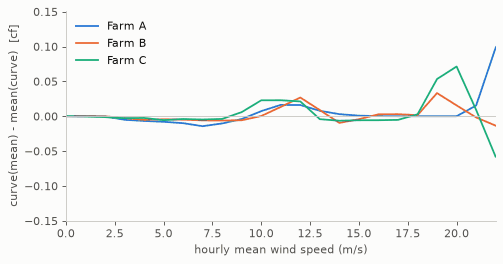

In [11]:
def curve_eval(farm, ws):
    b = np.clip(np.floor(np.nan_to_num(ws, nan=-1) / BIN).astype(int), 0, NBINS - 1)
    return np.where(np.isnan(ws), np.nan, REF10[farm].to_numpy()[b])


def theoretical(ws):
    ws = np.asarray(ws, float)
    return np.where((ws >= CUT_IN) & (ws < RATED), ((ws - CUT_IN) / (RATED - CUT_IN)) ** 3,
                    np.where((ws >= RATED) & (ws < CUT_OUT), 1.0, 0.0))


full6 = H[(H["n_clean"] == 6) & H["cf"].notna()].copy()
full6["curve_of_mean"] = np.nan
for f in FARMS:
    m = full6["farm"] == f
    full6.loc[m, "curve_of_mean"] = curve_eval(f, full6.loc[m, "ws"].to_numpy())
rows = []
for f, g in full6.groupby("farm"):
    e = g["cf"].sum()
    rows.append({"farm": f, "hours": len(g), "mean cf": g["cf"].mean(),
                 "curve(mean) - mean(curve), cf": (g["curve_of_mean"] - g["curve_of_10min"]).mean(),
                 "same, % of energy": 100 * (g["curve_of_mean"] - g["curve_of_10min"]).sum() / e,
                 "curve(mean) - true, % of energy": 100 * (g["curve_of_mean"] - g["cf"]).sum() / e,
                 "mean(curve) - true, % of energy": 100 * (g["curve_of_10min"] - g["cf"]).sum() / e,
                 "largest |bias| in a 1 m/s bin, cf": (g["curve_of_mean"] - g["curve_of_10min"]).groupby(g["ws"].round()).mean().abs().max()})
BIAS = pd.DataFrame(rows).set_index("farm").round(4)
display(BIAS)

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for f, c in zip(FARMS, [BLUE, ORANGE, AQUA]):
    g = full6[full6["farm"] == f]
    b = (g["curve_of_mean"] - g["curve_of_10min"]).groupby(g["ws"].round()).mean()
    ax.plot(b.index, b.values, c=c, lw=1.6, label=f"Farm {f}")
ax.axhline(0, c=MUTED, lw=0.8)
ax.set_xlim(0, 22)
ax.set_xlabel("hourly mean wind speed (m/s)")
ax.set_ylabel("curve(mean) - mean(curve)  [cf]")
ax.legend(frameon=False)
fig.tight_layout()
show(fig, "averaging_bias")

The averaging effect is negative in the convex part of the curve (the curve of the mean under-predicts) and positive
near rated, so it largely cancels over a week; the net figure per farm is in the table above. CatBoost is trained on
hourly means against hourly targets, so it learns the hourly relationship directly and the average bias is absorbed;
the hourly variability feature (`ws_sd3`) is only a weak proxy for the variability inside the hour. The bias matters
for the physical curves applied to an hourly forecast (baselines a and b), and the forecast itself is smoother than a
nacelle hourly mean, which belongs to the forecast-error discussion in section 9.

## 5. Features and the serving contract

| feature | from `park_wind_forecast` | in CARE (training proxy) | models |
|---|---|---|---|
| `ws` | `wind_speed_100m` (m/s) | hourly mean nacelle wind speed | all |
| `ws_d1` | `wind_speed_100m`(t) - (t-1 h) | same on the hourly series | all |
| `ws_sd3` | std of `wind_speed_100m` over t-1..t+1 h | same on the hourly series | all |
| `temp` | `temperature_2m` (C) minus the park's reference temperature | ambient minus the farm median (C is shifted) | per farm, pooled |
| `wd_sin`, `wd_cos` | `wind_direction_100m` (deg) | absolute wind direction (A `sensor_1`, B `sensor_4`; C has none) | per farm A/B, pooled |
| `hod_sin`, `hod_cos` | local solar hour of `forecast_time` (UTC + longitude / 15) | hour of the timestamp | all |
| `doy_sin`, `doy_cos` | day of year of `forecast_time` | day of year | all |
| `turbine` | turbine id | CARE turbine | per farm, pooled |
| `farm` | park id | CARE farm | pooled |

Notes:
- The cube of wind speed and wind bins are **not** separate features: a tree model is invariant to monotone transforms
  of a single feature, so `ws**3` or a binned `ws` carry no extra information for CatBoost. The curves (baselines) use
  bins.
- **Gusts** have only a loose counterpart: the 10-minute maximum at the nacelle against `wind_gusts_10m` at 10 m, and
  Farm A's max/mean ratio (median 1.9) differs from B and C (1.4), so the scales do not match. A gust factor is tested as
  an ablation only (section 10).
- **Pressure, humidity and dew point** do not exist in CARE, so they cannot be learned; `wind_speed_10m` and
  `wind_direction_10m` have no hub-height counterpart.
- **Direction, turbine and farm** are site-specific: what they learn about CARE terrain, wakes and individual machines
  does not transfer to a park that is not in CARE. Hence the **generic** model below has none of them, and none of the
  temperature centring either, because centring needs a site reference.

Models (all CatBoost, fixed parameters: depth 6, at most 600 trees, learning rate 0.05, L2 10, RMSE):
- **CatBoost per farm**: one model per farm, the full forecast set plus `turbine`.
- **CatBoost pooled**: one model for all three farms, the full forecast set plus `farm` and `turbine`.
- **CatBoost generic**: one model for all three farms with only `ws`, `ws_d1`, `ws_sd3`, hour and day of year: the
  candidate for parks and turbines outside CARE.
- **SCADA complete (diagnostic, not deployable)**: per farm, forecast set plus rotor speed, pitch and the 10-minute wind
  std and max of the hour. It shows the ceiling, not something that can run seven days ahead.

In [12]:
def add_wind_features(df, key):
    """ws_d1 and ws_sd3 from the hourly wind series, computed within `key` on a continuous hourly index."""
    g = df.groupby(key, sort=False)["ws"]
    df["ws_d1"] = df["ws"] - g.shift(1)
    df["ws_sd3"] = g.transform(lambda s: s.rolling(3, center=True, min_periods=2).std())
    return df


TEMP_REF = D.groupby("farm")["amb"].median().to_dict()   # farm reference temperature (centring; C is shifted)
H = add_wind_features(H, "segment")
H["temp"] = H["amb"] - H["farm"].map(TEMP_REF)
norm = np.hypot(H["wd_s"], H["wd_c"])
H["wd_sin"] = H["wd_s"] / norm
H["wd_cos"] = H["wd_c"] / norm
hod = H["hour"].dt.hour
H["hod_sin"], H["hod_cos"] = np.sin(2 * np.pi * hod / 24), np.cos(2 * np.pi * hod / 24)
doy = H["hour"].dt.dayofyear
H["doy_sin"], H["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
H["gust"] = H["ws_max"] / np.maximum(H["ws"], 1.0)

WIND = ["ws", "ws_d1", "ws_sd3"]
TIME = ["hod_sin", "hod_cos", "doy_sin", "doy_cos"]
DIR = ["wd_sin", "wd_cos"]
FEATS = {
    "farm": {f: WIND + ["temp"] + (DIR if f != "C" else []) + TIME + ["turbine"] for f in FARMS},
    "pooled": WIND + ["temp"] + DIR + TIME + ["farm", "turbine"],
    "generic": WIND + TIME,
    "scada": {f: WIND + ["temp"] + (DIR if f != "C" else []) + TIME + ["turbine", "rotor", "pitch", "ws_std10", "ws_max"] for f in FARMS},
}
CATS = ["turbine", "farm"]
print("farm reference temperatures (C):", {k: round(v, 1) for k, v in TEMP_REF.items()})
for k, v in FEATS.items():
    print(f"{k:8s}", v if isinstance(v, list) else v["A"])

farm reference temperatures (C): {'A': 20.0, 'B': 12.6, 'C': 28.1}
farm     ['ws', 'ws_d1', 'ws_sd3', 'temp', 'wd_sin', 'wd_cos', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'turbine']
pooled   ['ws', 'ws_d1', 'ws_sd3', 'temp', 'wd_sin', 'wd_cos', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'farm', 'turbine']
generic  ['ws', 'ws_d1', 'ws_sd3', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos']
scada    ['ws', 'ws_d1', 'ws_sd3', 'temp', 'wd_sin', 'wd_cos', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'turbine', 'rotor', 'pitch', 'ws_std10', 'ws_max']


## 6. Validation schemes

- **New turbines**: the ML1 folds from `cv_folds.parquet`, seed 0. Per-farm models use the `per_farm` scheme (A and B
  leave one turbine out, C five folds), pooled and generic models the `pooled` scheme (five folds over the 36 turbines).
  A held-out turbine's id is unseen, so CatBoost falls back to its prior for it.
- **Future**: inside every timeline the first 80% of its time span trains and the last 20% tests; no hour of a test
  period is used in training.

Early stopping is internal and grouped by turbine: the training turbines are split into three groups, each group is
held out once (fits on at most 150,000 rows), and the median best iteration is used to refit on all training rows.

In [13]:
FOLDS = pd.read_parquet(FOLDS_PATH)
FOLDS = FOLDS[FOLDS["seed"] == 0]
assert set(FOLDS["turbine"]) == set(H["turbine"]), "the ML1 folds do not cover the same turbines"
FOLD_OF = {s: FOLDS[FOLDS["scheme"] == s].set_index("turbine")["fold"].to_dict() for s in ["per_farm", "pooled"]}
span = H[H["ws"].notna()].groupby("segment")["hour"].agg(["min", "max"])
cutoff = span["min"] + FUTURE_FRAC * (span["max"] - span["min"])
H["future_test"] = H["hour"] >= H["segment"].map(cutoff)
H["has_target"] = H["cf"].notna() & H["ws"].notna()
H["has_input"] = H["ws"].notna()
display(FOLDS.groupby(["scheme", "farm"])["fold"].nunique().unstack())
print("future scheme, hours with target: train", int((H["has_target"] & ~H["future_test"]).sum()),
      "test", int((H["has_target"] & H["future_test"]).sum()))

farm      A  B  C
scheme           
per_farm  5  9  5
pooled    5  5  5

future scheme, hours with target: train 543591 test 118308


## 7. Quarter-hour table

**Re-binning, not interpolation.** Every 10-minute row is an average, so power and wind are taken as constant over its
10 minutes. Each row is split into two 5-minute halves and every quarter hour takes exactly three halves:
- quarter :00-:15 = (10 min of row :00 + 5 min of row :10) / 15;
- quarter :15-:30 = (5 min of row :10 + 10 min of row :20) / 15.

This conserves energy exactly: the four quarters of an hour average to the hour. The quarter's target `cf15` is kept
only when all three halves come from clean rows (section 3).

**The input wind is the hourly wind, interpolated.** At serving the forecast is hourly, so the model must not see wind
detail inside the hour that the forecast cannot give. Training therefore uses the hourly mean wind placed at the
centre of its hour and interpolated linearly to the centre of each quarter. The wind actually measured per quarter
is kept only for one diagnostic model.

In [14]:
TRAIN_MAX_ROWS = 500_000   # rows per final fit of a 15-minute model (quarters are strongly autocorrelated)
QUARTER_OFFSET = np.array([-0.375, -0.125, 0.125, 0.375])   # quarter centre minus hour centre, in hours
if FAST:
    TRAIN_MAX_ROWS = 60_000

minutes = D["time_stamp"].values.astype("datetime64[m]").astype(np.int64)
seg_code, seg_names = pd.factorize(D["segment"])
halves = pd.DataFrame({
    "s": np.concatenate([seg_code, seg_code]),
    "q": np.concatenate([minutes // 15, (minutes + 5) // 15]),
    "ws": np.tile(D["ws"].to_numpy(), 2), "p": np.tile(D["p"].to_numpy(), 2),
    "clean": np.tile(D["clean"].to_numpy(), 2)})
Q = halves.groupby(["s", "q"], sort=True).agg(n_half=("p", "size"), n_ws=("ws", "count"), ws_meas=("ws", "mean"),
                                               p_mean=("p", "mean"), n_clean=("clean", "sum")).reset_index()
del halves
Q["segment"] = seg_names[Q["s"].to_numpy()]
Q["quarter_start"] = pd.to_datetime(Q["q"] * 15, unit="m")
Q["hour"] = Q["quarter_start"].dt.floor("h")
Q["k"] = (Q["q"] % 4).astype(int)
Q["cf15"] = Q["p_mean"].where((Q["n_half"] == 3) & (Q["n_clean"] == 3))
Q["ws_meas"] = Q["ws_meas"].where(Q["n_ws"] == 3)
Q = Q.drop(columns=["s", "q", "p_mean"])

# energy check on hours whose four quarters all have a target
chk = Q[Q["cf15"].notna()].groupby(["segment", "hour"]).agg(n=("cf15", "size"), cf_q=("cf15", "mean"))
chk = chk[chk["n"] == 4].join(H.set_index(["segment", "hour"])["cf"])
chk = chk[chk["cf"].notna()]
print(f"quarters: {len(Q):,}, with a clean target: {int(Q['cf15'].notna().sum()):,}")
print(f"energy check on {len(chk):,} full hours: max |mean of 4 quarters - hourly cf| = {float((chk['cf_q'] - chk['cf']).abs().max()):.2e}")

quarters: 3,224,781, with a clean target: 2,616,655
energy check on 630,607 full hours: max |mean of 4 quarters - hourly cf| = 1.19e-07


In [15]:
H["ws_prev"] = H.groupby("segment")["ws"].shift(1)
H["ws_next"] = H.groupby("segment")["ws"].shift(-1)
HCOLS = ["ws", "ws_prev", "ws_next", "ws_d1", "ws_sd3", "temp", "wd_sin", "wd_cos", "doy_sin", "doy_cos", "turbine", "farm",
         "group", "week", "future_test", "cf", "has_input"]
Q = Q.merge(H[["segment", "hour"] + HCOLS].reset_index().rename(columns={"index": "hrow", "ws": "ws_hour", "cf": "cf_hour",
                                                                          "has_input": "hour_has_input"}),
            on=["segment", "hour"], how="left")
assert Q["hrow"].notna().all()


def interp_quarter(ws_hour, ws_prev, ws_next, k):
    """Linear interpolation of hourly values (placed at hour centres) to the centre of quarter k (0-3)."""
    d = QUARTER_OFFSET[k]
    nb = np.where(d < 0, ws_prev, ws_next)
    nb = np.where(np.isnan(nb), ws_hour, nb)
    return ws_hour + np.abs(d) * (nb - ws_hour)


def quarter_inputs(Qx):
    Qx["ws"] = interp_quarter(Qx["ws_hour"].to_numpy(), Qx["ws_prev"].to_numpy(), Qx["ws_next"].to_numpy(), Qx["k"].to_numpy())
    frac = Qx["hour"].dt.hour + (7.5 + 15 * Qx["k"]) / 60
    Qx["hod_sin"], Qx["hod_cos"] = np.sin(2 * np.pi * frac / 24), np.cos(2 * np.pi * frac / 24)
    Qx["quarter"] = Qx["k"]
    return Qx


Q = quarter_inputs(Q)
Q["has_target"] = Q["cf15"].notna() & Q["ws"].notna()
Q["has_input"] = Q["ws"].notna()
Q["day"] = Q["hour"].values.astype("datetime64[D]").astype(np.int64)
assert (Q.index == np.arange(len(Q))).all()
F15 = {
    "farm": {f: WIND + ["temp"] + (DIR if f != "C" else []) + TIME + ["quarter", "turbine"] for f in FARMS},
    "generic": WIND + TIME + ["quarter"],
}
print("15-minute features, farm A:", F15["farm"]["A"])
print("15-minute features, generic:", F15["generic"])
iq = Q["has_target"] & Q["ws_meas"].notna()
print(f"interpolated hourly wind vs measured quarter wind: r = {np.corrcoef(Q.loc[iq, 'ws'], Q.loc[iq, 'ws_meas'])[0, 1]:.3f}, "
      f"mean |difference| = {float((Q.loc[iq, 'ws'] - Q.loc[iq, 'ws_meas']).abs().mean()):.2f} m/s")
display(Q.groupby("farm").agg(quarters=("k", "size"), with_target=("has_target", "sum")))

15-minute features, farm A: ['ws', 'ws_d1', 'ws_sd3', 'temp', 'wd_sin', 'wd_cos', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'quarter', 'turbine']
15-minute features, generic: ['ws', 'ws_d1', 'ws_sd3', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'quarter']
interpolated hourly wind vs measured quarter wind: r = 0.993, mean |difference| = 0.33 m/s


      quarters  with_target
farm                       
A       676781       644827
B       537996       404223
C      2010004      1567605

## 8. Models and baselines at 15 minutes

Same splits as the hourly baseline: new turbines (ML1 folds, seed 0) and future (last 20% of every timeline).

| name | what it is |
|---|---|
| **CatBoost 15 min per farm** | one model per farm, forecast features at quarter resolution + quarter index + turbine |
| **CatBoost 15 min generic** | all farms, wind, hour, day of year and quarter index only (for parks outside CARE) |
| hourly CatBoost per farm, flat | the hourly ML2 baseline model, its hourly value repeated over the four quarters: **the bar** |
| empirical curve (median) | per farm, median `cf15` per 0.5 m/s bin of the interpolated wind |
| theoretical curve | 3 / 13 / 25 m/s on the interpolated wind |
| climatology | mean `cf15` per turbine and quarter of the day |
| true hourly value, flat (diagnostic) | the measured hourly mean repeated over the quarters: the best any flat profile can do |
| measured quarter wind (diagnostic, future only) | CatBoost per farm with the wind measured per quarter: what a perfect 15-minute forecast would give |

CatBoost parameters as before (depth 6, at most 600 trees, learning rate 0.05, L2 10, RMSE). Each 15-minute fit uses at
most 500,000 randomly drawn training quarters; the tree count comes from three inner fits grouped by turbine.

In [16]:
def frame(df, feats):
    X = df[feats].copy()
    for c in CATS:
        if c in X:
            X[c] = X[c].astype(str)
    return X


def inner_groups(turbines, seed, n=3):
    t = np.array(sorted(turbines))
    np.random.default_rng(1000 + seed).shuffle(t)
    k = min(n, len(t))
    return [t[i::k] for i in range(k)]


def subsample(idx, n, rng):
    return idx if len(idx) <= n else np.sort(rng.choice(idx, n, replace=False))


def fit_catboost(tr, feats, target, iterations=None, max_rows=None):
    rng = np.random.default_rng(SEED)
    if max_rows is not None and len(tr) > max_rows:
        tr = tr.iloc[subsample(np.arange(len(tr)), max_rows, rng)]
    if FAST:
        tr = tr.iloc[subsample(np.arange(len(tr)), 60_000, rng)]
    cats = [c for c in feats if c in CATS]
    X, y = frame(tr, feats), tr[target].to_numpy()
    inner = []
    if iterations is None:
        turbs = tr["turbine"].to_numpy()
        for g in inner_groups(np.unique(turbs), SEED):
            ev = np.isin(turbs, g)
            i_fit = subsample(np.flatnonzero(~ev), INNER_MAX_ROWS, rng)
            i_ev = subsample(np.flatnonzero(ev), INNER_MAX_ROWS // 2, rng)
            m = CatBoostRegressor(**CB_PARAMS)
            m.fit(X.iloc[i_fit], y[i_fit], cat_features=cats, eval_set=(X.iloc[i_ev], y[i_ev]), early_stopping_rounds=50,
                  use_best_model=False)
            inner.append(m.get_best_iteration() + 1)
        iterations = int(max(50, np.median(inner)))
    m = CatBoostRegressor(**{**CB_PARAMS, "iterations": iterations})
    m.fit(X, y, cat_features=cats)
    return m, iterations, inner


def fit_curve(ws, y):
    b = np.floor(ws / BIN).astype(int)
    s = pd.Series(y).groupby(b)
    v = s.median()[s.size() >= 20]
    return ((v.index.to_numpy() + 0.5) * BIN, v.to_numpy())


def eval_curve(c, ws):
    return np.interp(np.nan_to_num(ws, nan=0.0), c[0], c[1])


def theoretical(ws):
    ws = np.asarray(ws, float)
    return np.where((ws >= CUT_IN) & (ws < RATED), ((ws - CUT_IN) / (RATED - CUT_IN)) ** 3,
                    np.where((ws >= RATED) & (ws < CUT_OUT), 1.0, 0.0))


class Climatology15:
    def __init__(self, tr):
        qod = tr["hour"].dt.hour * 4 + tr["k"]
        self.t = tr.groupby([tr["turbine"], qod])["cf15"].mean().to_dict()
        self.f = tr.groupby([tr["farm"], qod])["cf15"].mean().to_dict()

    def __call__(self, df):
        qod = (df["hour"].dt.hour * 4 + df["k"]).to_numpy()
        return np.array([self.t.get((t, x), self.f.get((f, x), np.nan)) for t, f, x in zip(df["turbine"], df["farm"], qod)])


def splits(df, scheme, farms, fold_scheme):
    sub = df.index[df["farm"].isin(farms)]
    if scheme == "new":
        fo = df.loc[sub, "turbine"].map(FOLD_OF[fold_scheme])
        for k in sorted(fo.unique()):
            yield k, sub[(fo != k).to_numpy()], sub[(fo == k).to_numpy()]
    else:
        ft = df.loc[sub, "future_test"].to_numpy().astype(bool)
        yield 0, sub[~ft], sub[ft]


MODELS15 = {   # name -> (table, feature set, trained together, fold scheme, target, fixed trees, schemes)
    "CatBoost 15 min per farm": ("Q", "farm", "each", "per_farm", "cf15", None, ["new", "future"]),
    "CatBoost 15 min generic": ("Q", "generic", "all", "pooled", "cf15", None, ["new", "future"]),
    "hourly CatBoost per farm, flat": ("H", "hourly", "each", "per_farm", "cf", None, ["new", "future"]),
    "measured quarter wind (diagnostic)": ("QM", "farm", "each", "per_farm", "cf15", 600, ["future"]),
}
QM = Q.assign(ws=Q["ws_meas"])
TABLES = {"Q": Q, "H": H, "QM": QM}
FITTED15, ITERS15 = {}, []


def feats_for(fs, farm):
    if fs == "hourly":
        return FEATS["farm"][farm]
    return F15[fs][farm] if isinstance(F15[fs], dict) else F15[fs]


t_run = time.time()
for scheme in ["new", "future"]:
    for name, (tab, fs, together, fold_scheme, target, fixed, schemes) in MODELS15.items():
        if scheme not in schemes:
            continue
        df = TABLES[tab]
        FITTED15[(scheme, name)] = []
        for farms in ([[f] for f in FARMS] if together == "each" else [FARMS]):
            feats = feats_for(fs, farms[0])
            for k, tr_idx, te_idx in splits(df, scheme, farms, fold_scheme):
                tr = df.loc[tr_idx]
                tr = tr[tr["has_target"] & tr["ws"].notna()]
                t1 = time.time()
                m, n_it, inner = fit_catboost(tr, feats, target, fixed, TRAIN_MAX_ROWS if tab != "H" else None)
                ITERS15.append(dict(scheme=scheme, model=name, farms="".join(farms), fold=k, iterations=n_it, inner=inner,
                                    train_rows=len(tr), seconds=round(time.time() - t1, 1)))
                te = te_idx[df.loc[te_idx, "has_input"].to_numpy().astype(bool)]
                FITTED15[(scheme, name)].append(dict(te=te, model=m, feats=feats, table=tab, farms=farms))
    for name in ["empirical curve (median)", "theoretical curve", "climatology (turbine x quarter)"]:
        FITTED15[(scheme, name)] = []
    for f in FARMS:
        for k, tr_idx, te_idx in splits(Q, scheme, [f], "per_farm"):
            tr = Q.loc[tr_idx]
            tr = tr[tr["has_target"]]
            te = te_idx[Q.loc[te_idx, "has_input"].to_numpy()]
            FITTED15[(scheme, "empirical curve (median)")].append(dict(te=te, fn=lambda d, c=fit_curve(tr["ws"].to_numpy(), tr["cf15"].to_numpy()): eval_curve(c, d["ws"].to_numpy()), table="Q"))
            FITTED15[(scheme, "theoretical curve")].append(dict(te=te, fn=lambda d: theoretical(d["ws"].to_numpy()), table="Q"))
            FITTED15[(scheme, "climatology (turbine x quarter)")].append(dict(te=te, fn=Climatology15(tr), table="Q"))
ITERS15 = pd.DataFrame(ITERS15)
print(f"fitted in {time.time() - t_run:.0f} s")
display(ITERS15.groupby(["scheme", "model", "farms"]).agg(folds=("fold", "size"), median_trees=("iterations", "median"),
                                                           train_rows=("train_rows", "median"), seconds=("seconds", "sum")))


def predict15(scheme, Qsrc, Hsrc, models=None):
    """Quarter-level predictions of every fitted model of a scheme; hourly models are mapped to their quarters."""
    out = {}
    src = {"Q": Qsrc, "H": Hsrc, "QM": Qsrc.assign(ws=Qsrc["ws_meas"])}
    hrow = Qsrc["hrow"].to_numpy().astype(int)
    for (s, name), parts in FITTED15.items():
        if s != scheme or (models is not None and name not in models):
            continue
        tab = parts[0]["table"]
        p = np.full(len(src[tab]), np.nan)
        for part in parts:
            d = src[tab].loc[part["te"]]
            p[part["te"]] = part["model"].predict(frame(d, part["feats"])) if "model" in part else part["fn"](d)
        out[name] = p[hrow] if tab == "H" else p
    out_df = pd.DataFrame(out, index=Qsrc.index)
    if models is None or "true hourly value, flat (diagnostic)" in models:
        out_df["true hourly value, flat (diagnostic)"] = Qsrc["cf_hour"].to_numpy()
    return out_df


PRED15 = {s: predict15(s, Q, H) for s in ["new", "future"]}

fitted in 630 s


                                                 folds  median_trees  train_rows  seconds
scheme model                              farms                                          
future CatBoost 15 min generic            ABC        1         598.0   2148775.0      9.0
       CatBoost 15 min per farm           A          1         181.0    522779.0      9.9
                                          B          1         600.0    333764.0     23.6
                                          C          1         250.0   1292232.0     11.0
       hourly CatBoost per farm, flat     A          1         216.0    131049.0      6.6
                                          B          1         595.0     84089.0      9.7
                                          C          1         276.0    328453.0     11.5
       measured quarter wind (diagnostic) A          1         600.0    522779.0     12.7
                                          B          1         600.0    333764.0      8.6
          

## 9. Results at 15 minutes

- **15-minute metrics**: MAE, RMSE, R2 and bias on quarters with a clean target.
- **Shape inside the hour**: on hours with all four quarters, the deviation of each quarter from its hour's mean, true
  against predicted. R2 of the shape = 1 - sum((dev_true - dev_pred)^2) / sum(dev_true^2). A flat profile scores 0
  by construction. This is the direct test of whether the 15-minute model adds anything over the hourly one.
- **7-day energy**: per timeline and calendar week with at least 480 clean quarters (120 hours). WAPE and energy bias,
  energy = sum of `cf15` x 0.25 h.
- 95% intervals: cluster bootstrap over turbines, 1000 resamples, the same resamples for every model of a farm.

Pair accuracy is not repeated here: the ordering uses 7-day energy, which does not depend on the time step; see the
hourly baseline.

In [17]:
def boot_matrix(units, seed):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(units), size=(N_BOOT, len(units)))
    W = np.zeros((N_BOOT, len(units)))
    np.add.at(W, (np.repeat(np.arange(N_BOOT), len(units)), idx.ravel()), 1)
    return W


def ci(v):
    return np.nanpercentile(v, [2.5, 97.5])


def ratio_stats(d, num_cols, units, W):
    S = d.groupby("t")[num_cols].sum().reindex(units).fillna(0).to_numpy()
    return S.sum(0), W @ S


def metrics15(y, p, turb, hrow, units, W):
    d = pd.DataFrame({"t": turb, "n": 1.0, "e": p - y, "ae": np.abs(p - y), "se2": (p - y) ** 2, "y": y, "y2": y ** 2})
    pt, bt = ratio_stats(d, ["n", "e", "ae", "se2", "y", "y2"], units, W)

    def calc(t):
        n, e, ae, se2, sy, syy = (t[..., i] for i in range(6))
        return dict(mae=ae / n, rmse=np.sqrt(se2 / n), r2=1 - se2 / (syy - sy ** 2 / n), bias=e / n)

    a, b = calc(pt), calc(bt)
    out = {k: (float(a[k]), *ci(b[k])) for k in a}
    s = pd.DataFrame({"t": turb, "h": hrow, "y": y, "p": p})
    cnt = s.groupby("h")["y"].transform("size")
    s = s[cnt == 4]
    dt = s["y"] - s.groupby("h")["y"].transform("mean")
    dp = s["p"] - s.groupby("h")["p"].transform("mean")
    sh = pd.DataFrame({"t": s["t"], "sse": (dt - dp) ** 2, "sst": dt ** 2})
    pt, bt = ratio_stats(sh, ["sse", "sst"], units, W)
    out["shape_r2"] = (float(1 - pt[0] / pt[1]), *ci(1 - bt[:, 0] / bt[:, 1]))
    return out


def weekly15(df, pcol):
    g = df.groupby(["segment", "week"])
    w = pd.DataFrame({"n": g.size(), "E": g["cf15"].sum() * 0.25, "P": g[pcol].sum() * 0.25}).reset_index()
    w = w[w["n"] >= 4 * WEEK_MIN_HOURS]
    w["turbine"] = w["segment"].str.split("-").str[0]
    return w


def energy15(w, units, W):
    w = w.assign(ae=(w["P"] - w["E"]).abs(), e=w["P"] - w["E"], t=w["turbine"])
    pt, bt = ratio_stats(w, ["ae", "e", "E"], units, W)
    return dict(wape=(pt[0] / pt[2], *ci(bt[:, 0] / bt[:, 2])), ebias=(pt[1] / pt[2], *ci(bt[:, 1] / bt[:, 2])), weeks=len(w))


UNITS = {f: sorted(Q.loc[Q["farm"] == f, "turbine"].unique()) for f in FARMS}
BOOTW = {f: boot_matrix(UNITS[f], seed=100 + i) for i, f in enumerate(FARMS)}
EVAL15 = {"new": Q["has_target"].to_numpy(), "future": (Q["has_target"] & Q["future_test"].astype(bool)).to_numpy()}
Y15 = Q["cf15"].to_numpy()


def evaluate15(scheme, pred, models=None):
    rows = []
    for name in pred.columns if models is None else models:
        P = pred[name].to_numpy()
        for f in FARMS:
            m = EVAL15[scheme] & (Q["farm"] == f).to_numpy() & ~np.isnan(P)
            if m.sum() == 0:
                continue
            r = metrics15(Y15[m], P[m], Q["turbine"].to_numpy()[m], Q["hrow"].to_numpy()[m], UNITS[f], BOOTW[f])
            e = energy15(weekly15(Q.loc[m, ["segment", "week", "cf15"]].assign(pred=P[m]), "pred"), UNITS[f], BOOTW[f])
            rows.append({"scheme": scheme, "farm": f, "model": name, "R2 15 min": r["r2"], "MAE": r["mae"], "RMSE": r["rmse"],
                         "bias": r["bias"], "shape R2": r["shape_r2"], "WAPE 7d": e["wape"], "energy bias 7d": e["ebias"],
                         "weeks": e["weeks"]})
    return pd.DataFrame(rows)


def fmt(v, d=3):
    if isinstance(v, tuple):
        return f"{v[0]:.{d}f} [{v[1]:.{d}f}, {v[2]:.{d}f}]" if not np.isnan(v[0]) else "-"
    return f"{v:.{d}f}" if isinstance(v, float) else v


def point(v):
    return v[0] if isinstance(v, tuple) else v


RES15 = pd.concat([evaluate15(s, PRED15[s]) for s in ["new", "future"]], ignore_index=True)
ORDER15 = list(MODELS15) + ["empirical curve (median)", "theoretical curve", "climatology (turbine x quarter)",
                            "true hourly value, flat (diagnostic)"]
RES15["o"] = RES15["model"].map({m: i for i, m in enumerate(ORDER15)})
RES15 = RES15.sort_values(["scheme", "farm", "o"], ascending=[False, True, True]).drop(columns="o").reset_index(drop=True)
for s, title in [("new", "NEW TURBINES (ML1 folds)"), ("future", "FUTURE (last 20% of every timeline)")]:
    t = RES15[RES15["scheme"] == s]
    print(f"=== {title}")
    display(pd.DataFrame({"farm": t["farm"], "model": t["model"], "R2 15 min [95% CI]": t["R2 15 min"].map(fmt),
                          "MAE": t["MAE"].map(lambda v: f"{v[0]:.4f}"), "bias": t["bias"].map(lambda v: f"{v[0]:+.4f}"),
                          "shape R2 [95% CI]": t["shape R2"].map(fmt), "WAPE 7d [95% CI]": t["WAPE 7d"].map(fmt),
                          "energy bias 7d": t["energy bias 7d"].map(lambda v: f"{v[0]:+.3f}"), "weeks": t["weeks"]}).set_index(["farm", "model"]))

=== NEW TURBINES (ML1 folds)


                                               R2 15 min [95% CI]     MAE     bias       shape R2 [95% CI]      WAPE 7d [95% CI] energy bias 7d  weeks
farm model                                                                                                                                            
A    CatBoost 15 min per farm                0.969 [0.965, 0.973]  0.0336  +0.0050    0.260 [0.255, 0.266]  0.037 [0.019, 0.057]         +0.018    964
     CatBoost 15 min generic                 0.966 [0.961, 0.970]  0.0364  +0.0059    0.251 [0.245, 0.258]  0.036 [0.020, 0.056]         +0.021    964
     hourly CatBoost per farm, flat          0.963 [0.960, 0.966]  0.0378  +0.0014  -0.000 [-0.000, 0.000]  0.032 [0.019, 0.045]         +0.005    964
     empirical curve (median)                0.966 [0.964, 0.969]  0.0340  -0.0006    0.250 [0.243, 0.255]  0.041 [0.034, 0.048]         -0.002    964
     theoretical curve                       0.621 [0.576, 0.652]  0.1367  -0.1310    0.119 [0

=== FUTURE (last 20% of every timeline)


                                                R2 15 min [95% CI]     MAE     bias        shape R2 [95% CI]      WAPE 7d [95% CI] energy bias 7d  weeks
farm model                                                                                                                                              
A    CatBoost 15 min per farm                 0.972 [0.969, 0.974]  0.0320  -0.0008     0.256 [0.250, 0.263]  0.016 [0.012, 0.022]         -0.003    179
     CatBoost 15 min generic                  0.967 [0.962, 0.971]  0.0369  +0.0064     0.254 [0.249, 0.261]  0.032 [0.018, 0.049]         +0.022    179
     hourly CatBoost per farm, flat           0.966 [0.962, 0.969]  0.0353  -0.0010    0.000 [-0.000, 0.000]  0.013 [0.009, 0.018]         -0.003    179
     measured quarter wind (diagnostic)       0.997 [0.997, 0.998]  0.0100  -0.0012     0.964 [0.951, 0.974]  0.012 [0.007, 0.019]         -0.004    179
     empirical curve (median)                 0.968 [0.965, 0.972]  0.0339  +0.003

**15-minute model against the hourly model repeated over the quarters** (paired bootstrap over turbines).

In [18]:
def paired15(scheme, a, b):
    rows = []
    for f in FARMS:
        A_, B_ = PRED15[scheme][a].to_numpy(), PRED15[scheme][b].to_numpy()
        m = EVAL15[scheme] & (Q["farm"] == f).to_numpy() & ~np.isnan(A_) & ~np.isnan(B_)
        turb, hrow = Q["turbine"].to_numpy()[m], Q["hrow"].to_numpy()[m]
        res = {}
        for nm, P in [("a", A_), ("b", B_)]:
            d = pd.DataFrame({"t": turb, "n": 1.0, "se2": (P[m] - Y15[m]) ** 2, "y": Y15[m], "y2": Y15[m] ** 2})
            _, bt = ratio_stats(d, ["n", "se2", "y", "y2"], UNITS[f], BOOTW[f])
            res[nm + "r2"] = 1 - bt[:, 1] / (bt[:, 3] - bt[:, 2] ** 2 / bt[:, 0])
            w = weekly15(Q.loc[m, ["segment", "week", "cf15"]].assign(pred=P[m]), "pred")
            w = w.assign(ae=(w["P"] - w["E"]).abs(), t=w["turbine"])
            _, bt = ratio_stats(w, ["ae", "E"], UNITS[f], BOOTW[f])
            res[nm + "w"] = bt[:, 0] / bt[:, 1]
        r2d, wd = res["ar2"] - res["br2"], res["aw"] - res["bw"]
        rows.append({"scheme": scheme, "farm": f, "model": a, "against": b,
                     "R2 15 min difference [CI]": f"{np.median(r2d):+.4f} [{ci(r2d)[0]:+.4f}, {ci(r2d)[1]:+.4f}]",
                     "WAPE 7d difference [CI]": f"{np.median(wd):+.4f} [{ci(wd)[0]:+.4f}, {ci(wd)[1]:+.4f}]",
                     "better on R2": bool(ci(r2d)[0] > 0), "better on WAPE": bool(ci(wd)[1] < 0)})
    return rows


PAIRED15 = pd.DataFrame([r for s in ["new", "future"] for a, b in [("CatBoost 15 min per farm", "hourly CatBoost per farm, flat"),
                                                                      ("CatBoost 15 min per farm", "empirical curve (median)")]
                         for r in paired15(s, a, b)])
display(PAIRED15.set_index(["scheme", "farm", "model", "against"]))

                                                                      R2 15 min difference [CI]     WAPE 7d difference [CI]  better on R2  better on WAPE
scheme farm model                    against                                                                                                             
new    A    CatBoost 15 min per farm hourly CatBoost per farm, flat  +0.0066 [+0.0049, +0.0079]  +0.0049 [-0.0042, +0.0151]          True           False
       B    CatBoost 15 min per farm hourly CatBoost per farm, flat  +0.0054 [+0.0048, +0.0061]  -0.0000 [-0.0032, +0.0032]          True           False
       C    CatBoost 15 min per farm hourly CatBoost per farm, flat  +0.0041 [+0.0029, +0.0052]  +0.0053 [-0.0007, +0.0112]          True           False
       A    CatBoost 15 min per farm empirical curve (median)        +0.0027 [+0.0013, +0.0040]  -0.0048 [-0.0158, +0.0080]          True           False
       B    CatBoost 15 min per farm empirical curve (median)        +0.0141

## 10. Forecast-error sensitivity at 15 minutes

Same perturbation as the hourly baseline, applied to the **hourly** wind before it is interpolated to quarters (the
forecast error lives at the hourly level): shared by the time group, AR(1) with r = 0.95, standard deviation 1.5 / 2.2 /
3.3 m/s for lead times of 1 / 3 / 7 days, and a ramp from day 1 to day 7 within each week. These values are assumed,
not measured. Three draws each.

In [19]:
def unit_ar1(grid, rng):
    out = []
    for g, d in grid.groupby("group", sort=False):
        z = rng.standard_normal(len(d))
        e = np.empty(len(d))
        e[0] = z[0]
        a, b = NOISE_RHO, np.sqrt(1 - NOISE_RHO ** 2)
        for i in range(1, len(d)):
            e[i] = a * e[i - 1] + b * z[i]
        out.append(pd.DataFrame({"group": g, "hour": d["hour"].to_numpy(), "e": e}))
    return pd.concat(out, ignore_index=True)


GRID = pd.concat([pd.DataFrame({"group": g, "hour": pd.date_range(d["hour"].min(), d["hour"].max(), freq="h")})
                  for g, d in H[H["has_input"]].groupby("group")], ignore_index=True)


def sd_of(case, hours):
    if case != "ramp":
        return NOISE_SD[case]
    lead_days = (hours.values.astype("datetime64[h]").astype(np.int64) / 24.0) % 7 + 1 / 24
    return np.interp(lead_days, [1, 3, 7], [NOISE_SD["day 1"], NOISE_SD["day 3"], NOISE_SD["day 7"]])


def noisy_tables(case, rng):
    N = unit_ar1(GRID, rng)
    N["e"] = N["e"] * sd_of(case, N["hour"])
    Hn = H.drop(columns=["ws_d1", "ws_sd3"]).merge(N, on=["group", "hour"], how="left")
    Hn.index = H.index
    Hn["ws"] = np.maximum(Hn["ws"] + Hn["e"].fillna(0.0), 0.0)
    Hn = add_wind_features(Hn, "segment")
    Hn["ws_prev"] = Hn.groupby("segment")["ws"].shift(1)
    Hn["ws_next"] = Hn.groupby("segment")["ws"].shift(-1)
    Qn = Q.copy()
    hr = Q["hrow"].to_numpy().astype(int)
    for c_q, c_h in [("ws_hour", "ws"), ("ws_prev", "ws_prev"), ("ws_next", "ws_next"), ("ws_d1", "ws_d1"), ("ws_sd3", "ws_sd3")]:
        Qn[c_q] = Hn[c_h].to_numpy()[hr]
    return quarter_inputs(Qn), Hn


SENS15_MODELS = ["CatBoost 15 min per farm", "CatBoost 15 min generic", "hourly CatBoost per farm, flat", "empirical curve (median)"]
sens = []
t_s = time.time()
for case in ["none"] + list(NOISE_SD) + ["ramp"]:
    for k in range(1 if case == "none" else N_NOISE):
        Qn, Hn = (Q, H) if case == "none" else noisy_tables(case, np.random.default_rng(500 + k))
        for s in ["new", "future"]:
            r = evaluate15(s, predict15(s, Qn, Hn, SENS15_MODELS), SENS15_MODELS)
            r["case"], r["draw"] = case, k
            sens.append(r)
SENS15 = pd.concat(sens, ignore_index=True)
for c in ["R2 15 min", "shape R2", "WAPE 7d"]:
    SENS15[c] = SENS15[c].map(point)
SENS15_T = SENS15.groupby(["scheme", "farm", "model", "case"], sort=False)[["R2 15 min", "shape R2", "WAPE 7d"]].mean()
print(f"sensitivity in {time.time() - t_s:.0f} s")
for s in ["new", "future"]:
    print(f"=== {s.upper()}: R2 15 min / shape R2 / WAPE 7d by forecast-error case")
    t = SENS15_T.loc[s]
    display(pd.concat({c: t[c].unstack("case")[["none"] + list(NOISE_SD) + ["ramp"]] for c in ["R2 15 min", "shape R2", "WAPE 7d"]},
                      axis=1).round(3))

sensitivity in 78 s
=== NEW: R2 15 min / shape R2 / WAPE 7d by forecast-error case


                                    R2 15 min                             shape R2                             WAPE 7d                            
case                                     none  day 1  day 3  day 7   ramp     none  day 1  day 3  day 7   ramp    none  day 1  day 3  day 7   ramp
farm model                                                                                                                                        
A    CatBoost 15 min per farm           0.969  0.815  0.652  0.331  0.605    0.260  0.196  0.137  0.027  0.121   0.037  0.152  0.220  0.323  0.237
     CatBoost 15 min generic            0.966  0.807  0.641  0.324  0.596    0.251  0.181  0.117  0.003  0.101   0.036  0.151  0.218  0.317  0.235
     hourly CatBoost per farm, flat     0.963  0.816  0.661  0.355  0.616   -0.000 -0.000 -0.000 -0.000 -0.000   0.032  0.145  0.212  0.312  0.228
     empirical curve (median)           0.966  0.815  0.654  0.330  0.606    0.250  0.190  0.133  0.021  0.115   0.041

=== FUTURE: R2 15 min / shape R2 / WAPE 7d by forecast-error case


                                    R2 15 min                             shape R2                             WAPE 7d                            
case                                     none  day 1  day 3  day 7   ramp     none  day 1  day 3  day 7   ramp    none  day 1  day 3  day 7   ramp
farm model                                                                                                                                        
A    CatBoost 15 min per farm           0.972  0.820  0.665  0.368  0.619    0.256  0.196  0.140  0.038  0.125   0.016  0.137  0.197  0.285  0.214
     CatBoost 15 min generic            0.967  0.808  0.649  0.351  0.604    0.254  0.187  0.124  0.014  0.109   0.032  0.141  0.201  0.287  0.218
     hourly CatBoost per farm, flat     0.966  0.816  0.664  0.371  0.619    0.000  0.000  0.000  0.000  0.000   0.013  0.135  0.195  0.282  0.212
     empirical curve (median)           0.968  0.812  0.653  0.346  0.605    0.253  0.190  0.134  0.029  0.119   0.032

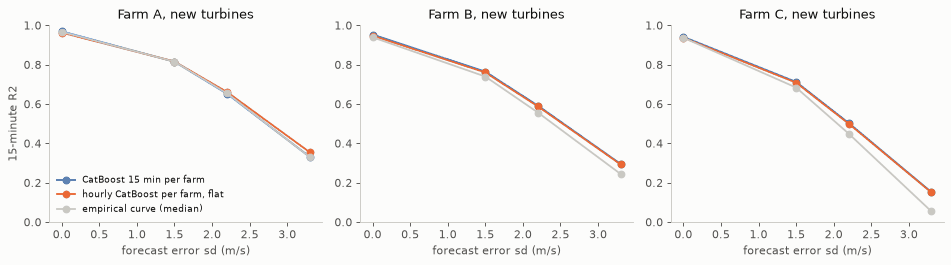

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
cases = ["none"] + list(NOISE_SD)
xs = [0] + list(NOISE_SD.values())
for ax, f in zip(axes, FARMS):
    for name, c in [("CatBoost 15 min per farm", BLUE), ("hourly CatBoost per farm, flat", ORANGE), ("empirical curve (median)", MUTED)]:
        ax.plot(xs, [SENS15_T.loc[("new", f, name, cs), "R2 15 min"] for cs in cases], c=c, marker="o", lw=1.6, label=name)
    ax.set_title(f"Farm {f}, new turbines")
    ax.set_xlabel("forecast error sd (m/s)")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("15-minute R2")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
show(fig, "forecast_error_sensitivity_15min")

## 11. One week ahead, every 15 minutes: the serving path

This is what ML2 at 15 minutes does at serving, on one test week of the future scheme (a Farm C turbine, the week with
the most clean quarters):
1. **Input:** 168 hourly forecast rows shaped like `park_wind_forecast` (`forecast_time`, `wind_speed_100m`,
   `temperature_2m`, `wind_direction_100m`). As a stand-in for the forecast, the measured wind at each full hour is
   used: the mean of the two 10-minute rows next to the hour mark, which approximates an instantaneous value as
   Open-Meteo gives it.
2. **Quarter rows:** each hour T gives quarters starting at T, T+15, T+30 and T+45 min. Wind at the quarter centre is
   interpolated linearly between the forecast values at T and T+1 h; the last hour holds its value. The hourly
   features (`ws_d1`, `ws_sd3`, temperature, direction) apply to the hour's four quarters.
3. **Prediction:** the model of the future scheme (trained on the first 80% of each timeline, so this week is unseen)
   gives `cf` per quarter, clipped to [0, 1]. kW = cf x capacity_kw, kWh = kW x 0.25. The capacity used is 2050 kW,
   the database default.

The same week is also run with a forecast error that grows from 1.5 m/s on day 1 to 3.3 m/s on day 7 (one draw).

demo: timeline C23-2, week starting 2029-01-18 (anonymised CARE date), 672 quarter-hour rows, 672 with a clean measured value


  turbine       quarter_start  ws_interp  cf_pred_farm_model  power_kw_farm_model  energy_kwh_farm_model  cf_pred_generic  cf_pred_farm_model_ramp_error  cf_measured
0     C23 2029-01-18 00:00:00   6.418750            0.194181           398.070599              99.517650         0.210035                       0.204265     0.184769
1     C23 2029-01-18 00:15:00   6.434250            0.194181           398.070599              99.517650         0.211519                       0.204876     0.245275
2     C23 2029-01-18 00:30:00   6.449750            0.204111           418.427974             104.606993         0.219447                       0.210389     0.208785
3     C23 2029-01-18 00:45:00   6.465250            0.204016           418.233528             104.558382         0.213820                       0.220255     0.210105
4     C23 2029-01-18 01:00:00   6.541063            0.265624           544.528309             136.132077         0.259835                       0.281888     0.190565
5   

                                                   MAE per quarter  predicted MWh (clean quarters)  measured MWh (clean quarters)
model                                                                                                                            
CatBoost 15 min per farm (measured-wind stand-in)            0.026                          63.471                         62.967
CatBoost 15 min generic (same input)                         0.026                          62.367                         62.967
CatBoost 15 min per farm, ramp forecast error                0.135                          18.119                         62.967

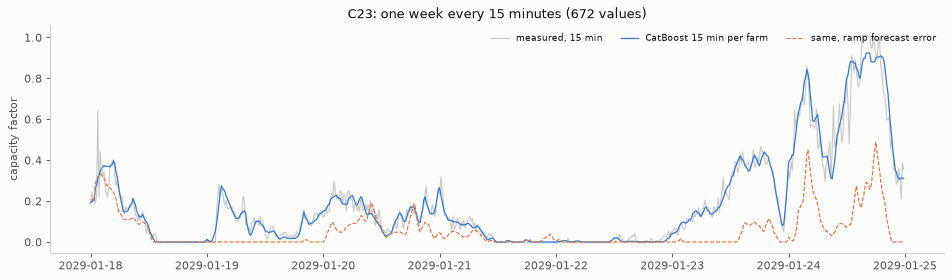

In [21]:
def quarters_from_forecast(fc, longitude=0.0, ref_temp=0.0):
    """Quarter-hour feature rows from hourly forecast rows (instantaneous values at `forecast_time`)."""
    fc = fc.sort_values("forecast_time").reset_index(drop=True)
    v = fc["wind_speed_100m"].to_numpy(float)
    nxt = np.append(v[1:], np.nan)
    d1 = v - np.insert(v[:-1], 0, np.nan)
    sd3 = pd.Series(v).rolling(3, center=True, min_periods=2).std().to_numpy()
    rad = np.radians(fc["wind_direction_100m"].to_numpy(float))
    t = fc["forecast_time"]
    doy = t.dt.dayofyear.to_numpy()
    rows = []
    for k in range(4):
        frac = (7.5 + 15 * k) / 60
        local = (t.dt.hour.to_numpy() + t.dt.minute.to_numpy() / 60 + frac + longitude / 15) % 24
        rows.append(pd.DataFrame({
            "quarter_start": t + pd.Timedelta(minutes=15 * k),
            "ws": np.where(np.isnan(nxt), v, v + frac * (nxt - v)), "ws_d1": d1, "ws_sd3": sd3,
            "temp": fc["temperature_2m"].to_numpy(float) - ref_temp, "wd_sin": np.sin(rad), "wd_cos": np.cos(rad),
            "hod_sin": np.sin(2 * np.pi * local / 24), "hod_cos": np.cos(2 * np.pi * local / 24),
            "doy_sin": np.sin(2 * np.pi * doy / 365.25), "doy_cos": np.cos(2 * np.pi * doy / 365.25), "quarter": k}))
    return pd.concat(rows, ignore_index=True).sort_values("quarter_start").reset_index(drop=True)


def predict_week_15min(fc, model, feats, capacity_kw, longitude=0.0, ref_temp=0.0, turbine=None, farm=None):
    """Capacity factor, kW and kWh for every quarter hour covered by the hourly forecast rows."""
    X = quarters_from_forecast(fc, longitude, ref_temp)
    X["turbine"], X["farm"] = turbine, farm
    cf = np.clip(model.predict(frame(X, feats)), 0.0, 1.0)
    out = pd.DataFrame({"quarter_start": X["quarter_start"], "ws_interp": X["ws"], "cf": cf})
    out["power_kw"] = out["cf"] * capacity_kw
    out["energy_kwh"] = out["power_kw"] * 0.25
    return out


cand = Q[EVAL15["future"] & (Q["farm"] == "C").to_numpy()].groupby(["segment", "week"]).size().reset_index(name="n")
pick = cand.sort_values(["n", "segment", "week"], ascending=[False, True, True]).iloc[0]
seg, wk = pick["segment"], int(pick["week"])
turb, farm = seg.split("-")[0], seg[0]
week_start = pd.Timestamp(wk * 7, unit="D")
hours = pd.date_range(week_start, periods=168, freq="h")
ds = D[D["segment"] == seg].set_index("time_stamp")
inst = [(ds["ws"].get(h - pd.Timedelta(minutes=10), np.nan) + ds["ws"].get(h, np.nan)) / 2 for h in hours]
hs = H[H["segment"] == seg].set_index("hour")
FC = pd.DataFrame({"forecast_time": hours, "wind_speed_100m": pd.Series(inst).interpolate(limit_direction="both").to_numpy(),
                   "temperature_2m": hs["amb"].reindex(hours).interpolate(limit_direction="both").to_numpy(),
                   "wind_direction_100m": np.nan})
part_farm = [p for p in FITTED15[("future", "CatBoost 15 min per farm")] if p["farms"] == [farm]][0]
part_gen = FITTED15[("future", "CatBoost 15 min generic")][0]
CAP = 2050.0
wk_farm = predict_week_15min(FC, part_farm["model"], part_farm["feats"], CAP, ref_temp=TEMP_REF[farm], turbine=turb, farm=farm)
wk_gen = predict_week_15min(FC, part_gen["model"], part_gen["feats"], CAP)
rng = np.random.default_rng(7)
z = rng.standard_normal(168)
e = np.empty(168)
e[0] = z[0]
for i in range(1, 168):
    e[i] = NOISE_RHO * e[i - 1] + np.sqrt(1 - NOISE_RHO ** 2) * z[i]
FC_noisy = FC.assign(wind_speed_100m=np.maximum(FC["wind_speed_100m"] + e * sd_of("ramp", FC["forecast_time"]), 0.0))
wk_noisy = predict_week_15min(FC_noisy, part_farm["model"], part_farm["feats"], CAP, ref_temp=TEMP_REF[farm], turbine=turb, farm=farm)
truth = Q[(Q["segment"] == seg)].set_index("quarter_start")["cf15"]
DEMO = wk_farm.rename(columns={"cf": "cf_pred_farm_model", "power_kw": "power_kw_farm_model", "energy_kwh": "energy_kwh_farm_model"})
DEMO["cf_pred_generic"] = wk_gen["cf"].to_numpy()
DEMO["cf_pred_farm_model_ramp_error"] = wk_noisy["cf"].to_numpy()
DEMO["cf_measured"] = truth.reindex(DEMO["quarter_start"]).to_numpy()
DEMO.insert(0, "turbine", turb)
print(f"demo: timeline {seg}, week starting {week_start.date()} (anonymised CARE date), {len(DEMO)} quarter-hour rows, "
      f"{int(DEMO['cf_measured'].notna().sum())} with a clean measured value")
display(DEMO.head(8))
ok = DEMO["cf_measured"].notna()
demo_rows = []
for col, label in [("cf_pred_farm_model", "CatBoost 15 min per farm (measured-wind stand-in)"),
                   ("cf_pred_generic", "CatBoost 15 min generic (same input)"),
                   ("cf_pred_farm_model_ramp_error", "CatBoost 15 min per farm, ramp forecast error")]:
    demo_rows.append({"model": label, "MAE per quarter": float((DEMO.loc[ok, col] - DEMO.loc[ok, "cf_measured"]).abs().mean()),
                      "predicted MWh (clean quarters)": float(DEMO.loc[ok, col].sum() * CAP * 0.25 / 1000),
                      "measured MWh (clean quarters)": float(DEMO.loc[ok, "cf_measured"].sum() * CAP * 0.25 / 1000)})
display(pd.DataFrame(demo_rows).set_index("model").round(3))

fig, ax = plt.subplots(figsize=(12, 3.6))
x = DEMO["quarter_start"]
ax.plot(x, DEMO["cf_measured"], c=MUTED, lw=1.0, label="measured, 15 min")
ax.plot(x, DEMO["cf_pred_farm_model"], c=BLUE, lw=1.1, label="CatBoost 15 min per farm")
ax.plot(x, DEMO["cf_pred_farm_model_ramp_error"], c=ORANGE, lw=1.0, ls="--", label="same, ramp forecast error")
ax.set_ylabel("capacity factor")
ax.set_title(f"{turb}: one week every 15 minutes (672 values)")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
fig.tight_layout()
show(fig, "demo_week_15min")

## 12. Final models, feature contract, predictions

Final 15-minute models are refitted on all quarters with a clean target (at most 1,000,000 randomly drawn per model),
with the tree count set to the median of the new-turbine folds; a file over the 500 KB limit keeps only its first trees.

In [22]:
MAX_MODEL_BYTES = 480_000
FINAL15 = {
    "ml2_cf15_farm_A.cbm": ("CatBoost 15 min per farm", ["A"], F15["farm"]["A"]),
    "ml2_cf15_farm_B.cbm": ("CatBoost 15 min per farm", ["B"], F15["farm"]["B"]),
    "ml2_cf15_farm_C.cbm": ("CatBoost 15 min per farm", ["C"], F15["farm"]["C"]),
    "ml2_cf15_generic.cbm": ("CatBoost 15 min generic", FARMS, F15["generic"]),
}
final_rows, importance = [], {}
for fname, (model, farms, feats) in FINAL15.items():
    n_it = int(ITERS15[(ITERS15["scheme"] == "new") & (ITERS15["model"] == model) & (ITERS15["farms"] == "".join(farms))]["iterations"].median())
    tr = Q[Q["farm"].isin(farms) & Q["has_target"]]
    m, _, _ = fit_catboost(tr, feats, "cf15", n_it, 1_000_000)
    m.save_model(str(MODELS / fname))
    size = (MODELS / fname).stat().st_size
    kept, change = n_it, 0.0
    if size >= MAX_MODEL_BYTES:
        Xs = frame(tr.iloc[:: max(1, len(tr) // 200_000)], feats)
        full_pred = m.predict(Xs)
        kept = int(n_it * MAX_MODEL_BYTES / size * 0.98)
        while True:   # file size is not proportional to the tree count, so shrink until it fits
            m.shrink(ntree_end=kept)
            m.save_model(str(MODELS / fname))
            size = (MODELS / fname).stat().st_size
            if size < MAX_MODEL_BYTES:
                break
            kept = int(kept * 0.95)
        change = float(np.sqrt(np.mean((m.predict(Xs) - full_pred) ** 2)))
    assert size < 500_000, f"{fname} is {size} bytes"
    importance[fname] = pd.Series(m.get_feature_importance(), index=feats).round(1)
    final_rows.append({"file": fname, "model": model, "trees (CV median)": n_it, "trees kept": kept,
                       "RMS change from dropped trees (cf)": round(change, 5), "training quarters": min(len(tr), 1_000_000),
                       "size KB": round(size / 1024, 1)})
display(pd.DataFrame(final_rows).set_index("file"))
display(pd.concat(importance, axis=1).fillna(0).sort_values("ml2_cf15_generic.cbm", ascending=False))

                                         model  trees (CV median)  trees kept  RMS change from dropped trees (cf)  training quarters  size KB
file                                                                                                                                         
ml2_cf15_farm_A.cbm   CatBoost 15 min per farm                427         406                             0.00057             644827    460.1
ml2_cf15_farm_B.cbm   CatBoost 15 min per farm                600         363                             0.00806             404223    454.4
ml2_cf15_farm_C.cbm   CatBoost 15 min per farm                213         213                             0.00000            1000000    277.3
ml2_cf15_generic.cbm   CatBoost 15 min generic                600         418                             0.00363            1000000    466.8

         ml2_cf15_farm_A.cbm  ml2_cf15_farm_B.cbm  ml2_cf15_farm_C.cbm  ml2_cf15_generic.cbm
ws                      91.2                 85.2                 92.3                  91.7
doy_cos                  0.8                  2.8                  1.6                   3.7
doy_sin                  0.3                  2.7                  1.2                   1.9
ws_d1                    2.8                  1.7                  0.9                   1.4
ws_sd3                   0.7                  0.3                  0.0                   0.4
hod_sin                  0.4                  0.6                  0.1                   0.4
hod_cos                  0.6                  0.4                  0.2                   0.4
temp                     1.3                  2.0                  1.0                   0.0
wd_sin                   0.4                  1.2                  0.0                   0.0
wd_cos                   0.3                  1.9                  0.0

In [23]:
def head15(model, scheme, farm):
    r = RES15[(RES15["scheme"] == scheme) & (RES15["model"] == model) & (RES15["farm"] == farm)].iloc[0]
    return {"R2_15min": round(point(r["R2 15 min"]), 3), "shape_R2": round(point(r["shape R2"]), 3),
            "WAPE_7d": round(point(r["WAPE 7d"]), 3)}


CONTRACT15 = {
    "name": "ML2 15-minute variant: available production per turbine and quarter hour",
    "created": "2026-11-08",
    "notebook": "notebooks/care_ml2_power_15min.ipynb",
    "results": "notebooks/care_ml2_power_15min.md",
    "hourly_contract": "models/ml2/feature_contract.json (same target definition and hourly features)",
    "target": {"name": "cf15", "unit": "capacity factor (1.0 = rated power)",
               "definition": "mean power over the quarter hour of a healthy turbine in operation, without stops and curtailment"},
    "source_table": "park_wind_forecast (hourly, unchanged)",
    "output": "one row per quarter hour: quarter_start (UTC), cf; 7 days of forecast = 168 hourly rows = 672 quarters",
    "output_to_energy": "kWh per quarter = clip(cf, 0, 1) * capacity_kw * 0.25; MWh over the week = sum / 1000",
    "quarter_rows": {
        "starts": "for each forecast hour T: T, T+15 min, T+30 min, T+45 min",
        "ws": "wind_speed_100m interpolated linearly to the quarter centre (T + 7.5 + 15 k min) between the values at T and T + 1 h; "
              "the last forecast hour holds its value",
        "ws_d1, ws_sd3": "computed on the hourly wind_speed_100m series as in the hourly contract, applied to the hour's four quarters",
        "temp": "temperature_2m of the hour minus the park reference temperature (farm models only)",
        "wd_sin, wd_cos": "sin/cos of wind_direction_100m of the hour (farm models A and B only)",
        "hod_sin, hod_cos": "local solar time of the quarter centre: (UTC hour + minutes / 60 + (7.5 + 15 k) / 60 + longitude / 15) mod 24",
        "doy_sin, doy_cos": "day of year of the UTC date",
        "quarter": "k = 0, 1, 2, 3 (position in the hour)",
        "turbine, farm": "CARE ids as strings (farm models only)",
    },
    "time_convention": ("training placed each hourly mean at the centre of its hour; serving treats each Open-Meteo hourly value as "
                        "the instantaneous wind at forecast_time. Both interpolate a smooth wind to the quarter centre."),
    "models": {
        "ml2_cf15_generic.cbm": {"features": F15["generic"], "use": "parks and turbines outside CARE",
                                 "new_turbines": {f: head15("CatBoost 15 min generic", "new", f) for f in FARMS}},
        **{f"ml2_cf15_farm_{f}.cbm": {"features": F15["farm"][f], "use": f"CARE farm {f} turbines only",
                                      "new_turbines": head15("CatBoost 15 min per farm", "new", f),
                                      "future": head15("CatBoost 15 min per farm", "future", f)} for f in FARMS},
    },
    "categorical_features": "turbine and farm as strings",
    "missing_values": "NaN allowed; wd_sin and wd_cos are NaN for farm C",
    "limits": [
        "trained on measured nacelle wind (hourly mean, interpolated), served on forecast wind: metrics are an upper bound",
        "the forecast is hourly, so detail inside the hour cannot be predicted; the quarter profile is a smooth interpolation",
    ],
}
(MODELS / "feature_contract_15min.json").write_text(json.dumps(CONTRACT15, indent=2) + "\n", encoding="utf-8")

QP = Q.loc[EVAL15["future"], ["farm", "turbine", "segment", "group", "quarter_start", "ws", "cf15"]].rename(columns={"ws": "ws_interp"})
for col, name in [("cf_pred_15min_farm", "CatBoost 15 min per farm"), ("cf_pred_15min_generic", "CatBoost 15 min generic"),
                  ("cf_pred_hourly_flat", "hourly CatBoost per farm, flat"), ("cf_pred_empirical_curve", "empirical curve (median)")]:
    QP[col] = PRED15["future"][name].to_numpy()[EVAL15["future"]]
QP.to_parquet(OUT / "ml2_15min_predictions_future.parquet", index=False)
DEMO.to_parquet(OUT / "ml2_15min_demo_week.parquet", index=False)

weekly = []
for s in ["new", "future"]:
    m = EVAL15[s]
    base = Q.loc[m, ["farm", "turbine", "segment", "group", "week", "cf15"]].copy()
    cols = {"energy_15min_farm_cfh": "CatBoost 15 min per farm", "energy_15min_generic_cfh": "CatBoost 15 min generic",
            "energy_hourly_flat_cfh": "hourly CatBoost per farm, flat", "energy_empirical_curve_cfh": "empirical curve (median)"}
    for col, name in cols.items():
        base[col] = PRED15[s][name].to_numpy()[m] * 0.25
    base["cf15"] = base["cf15"] * 0.25
    g = base.groupby(["farm", "turbine", "segment", "group", "week"])
    w = g["cf15"].agg(["size", "sum"]).rename(columns={"size": "clean_quarters", "sum": "energy_true_cfh"})
    for col in cols:
        w[col] = g[col].sum()
    w = w[w["clean_quarters"] >= 4 * WEEK_MIN_HOURS].reset_index()
    w.insert(0, "scheme", "new_turbines" if s == "new" else "future")
    w["week_start"] = pd.to_datetime(w["week"] * 7, unit="D")
    weekly.append(w)
pd.concat(weekly, ignore_index=True).to_parquet(OUT / "ml2_15min_weekly.parquet", index=False)

R = RES15.copy()
for c in R.columns:
    if R[c].map(lambda v: isinstance(v, tuple)).any():
        R[c + " lo"], R[c + " hi"], R[c] = R[c].map(lambda v: v[1]), R[c].map(lambda v: v[2]), R[c].map(lambda v: v[0])
R.to_csv(OUT / "results_15min_main.csv", index=False)
SENS15_T.reset_index().to_csv(OUT / "results_15min_forecast_error.csv", index=False)
PAIRED15.to_csv(OUT / "results_15min_paired.csv", index=False)
ITERS15.to_csv(OUT / "iterations_15min.csv", index=False)
print("written:", sorted(p.name for p in OUT.iterdir() if "15min" in p.name), sorted(p.name for p in MODELS.iterdir() if "15" in p.name))

written: ['demo_week_15min.png', 'forecast_error_sensitivity_15min.png', 'iterations_15min.csv', 'ml2_15min_demo_week.parquet', 'ml2_15min_predictions_future.parquet', 'ml2_15min_weekly.parquet', 'results_15min_forecast_error.csv', 'results_15min_main.csv', 'results_15min_paired.csv'] ['feature_contract_15min.json', 'ml2_cf15_farm_A.cbm', 'ml2_cf15_farm_B.cbm', 'ml2_cf15_farm_C.cbm', 'ml2_cf15_generic.cbm']


## 13. Summary

The interpretation is in `notebooks/care_ml2_power_15min.md`.

In [24]:
t = RES15[RES15["model"].isin(["CatBoost 15 min per farm", "CatBoost 15 min generic", "hourly CatBoost per farm, flat",
                                "empirical curve (median)", "true hourly value, flat (diagnostic)", "measured quarter wind (diagnostic)"])]
display(pd.DataFrame({"scheme": t["scheme"], "farm": t["farm"], "model": t["model"], "R2 15 min": t["R2 15 min"].map(lambda v: round(v[0], 3)),
                      "shape R2": t["shape R2"].map(lambda v: round(v[0], 3)), "WAPE 7d": t["WAPE 7d"].map(lambda v: round(v[0], 3))}).set_index(["scheme", "farm", "model"]))
print(f"total run time {(time.time() - T0) / 60:.1f} min")

                                                  R2 15 min  shape R2  WAPE 7d
scheme farm model                                                             
new    A    CatBoost 15 min per farm                  0.969     0.260    0.037
            CatBoost 15 min generic                   0.966     0.251    0.036
            hourly CatBoost per farm, flat            0.963    -0.000    0.032
            empirical curve (median)                  0.966     0.250    0.041
            true hourly value, flat (diagnostic)      0.969     0.000    0.000
       B    CatBoost 15 min per farm                  0.953     0.222    0.035
            CatBoost 15 min generic                   0.906     0.191    0.133
            hourly CatBoost per farm, flat            0.948     0.000    0.035
            empirical curve (median)                  0.939     0.209    0.041
            true hourly value, flat (diagnostic)      0.975     0.000    0.000
       C    CatBoost 15 min per farm                

total run time 13.1 min
